# 🚀 Proiect 1 - Predicția plecării clienților (Telco Customer Churn)

🗄️ 1. Explorarea datelor

📚 1.a) Se încarcă bibliotecile și setul de date

`pandas` e o bibliotecă pentru organizarea, prelucrarea și analiza datelor în tabel. `matplotlib` e o bibliotecă pentru crearea graficelor și vizualizarea datelor. `seaborn` e bazată pe `matplotlib` și creează grafice mai simplu și mai intuitiv.

Folosesc metoda `df.head()` pentru a vedea cum sunt organizate datele și a verifica dacă au fost încărcate corect.

Coloanele cele mai relevante
| Coloana | Explicație |
|---|---|
| tenure | De câte luni e clientul abonat |
| Contract | Tipul contractului: lunar, 1 an, 2 ani |
| MonthlyCharges | Cât plătește pe lună |
| TotalCharges | Cât a plătit în total până acum |
| Churn | "Yes" (=a plecat), "No" (=a rămas) |

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

📏 1.b) Verific dimensiunea și tipurile coloanelor pentru a înțelege cum sunt organizate datele și dacă sunt pregătite pentru analiză.

In [ ]:
print(f"Dimensiune (randuri, coloane): {df.shape}")
df.info()

**👀 Interpretare:** Setul conține 7.043 de clienți și 21 de coloane (3 coloane numerice și 18 de tip text). `TotalCharges` conține sume, dar este citită ca text. Trebuie să verific valorile și să o convertesc în format numeric pentru a putea analiza corect sumele și a o folosi în modelele de ML.

⭕ 1.c) Convertesc `TotalCharges` în număr pentru a putea analiza sumele. Cu `errors="coerce"`, valorile care nu pot fi convertite devin `NaN`, apoi verific câte valori lipsesc.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isna().sum())

Vreau să verific dacă valorile lipsă din `TotalCharges` au legătură cu vechimea contractului și taxa lunară a clienților.

In [ ]:
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

**👀 Interpretare:** Cele 11 valori lipsă apar la clienții cu `tenure = 0`, adică sunt la începutul contractului și nu au plătit încă nicio sumă. Deși `TotalCharges` lipsește, `MonthlyCharges` are o valoare, deci acești clienți au deja o taxă lunară stabilită.

📈 1.d) Mă uit câți clienți pleacă și câți rămân

In [ ]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Grafic 1: Câți pleacă vs câți rămân

In [ ]:
sns.countplot(data=df, x="Churn")
plt.title("Câți clienți pleacă (Yes) vs rămân (No)")
plt.show()

**👀Interpretare:**
Bara "No" este mai înaltă decât bara "Yes": din totalul de 7043 de clienți, 73.46% au rămas, iar 26.54% au renunțat la servicii. Asta înseamnă că datele sunt dezechilibrate. Un model care ar răspunde mereu "No" ar avea o acuratețe de ~73%, fără să învețe nimic. De aceea ne vom uita mai mult la recall pe clasa "Yes", împreună cu precision și F1.

Grafic 2: Calculez procentele ca să văd mai ușor ce tip de contract are cea mai mare rată de plecare a clienților.

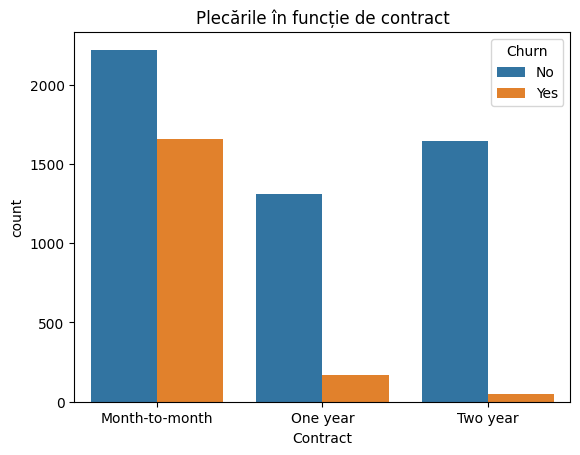

In [11]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Plecările în funcție de contract")
plt.show()

**👀Interpretare:** Clienții cu contract lunar pleacă cel mai des (43%), față de cei cu contract pe un an (11%) și cei cu contract pe doi ani (3%). Probabil, cei cu contract lunar se pot răzgândi mai ușor, pentru că nu sunt legați de un contract pe termen lung.

Graficul 3: Vechimea clientului

In [ ]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Vechimea clientului (luni) vs plecare")
plt.show()

**👀Interpretare:** Majoritatea plecărilor (portocaliu Yes) sunt la clienții noi (stânga) nu la cei vechi (dreapta).